# Transferring the 2024 black-box optimisation archive

Assess each function against the collaborative 2024 archive. Compare measured bests, inspect repeated measurements, and test whether adding the historical rows improves prediction on nine confirmed returns per function. Four query opportunities remain in the current course. The proposed batch remains in the [Week 10 decision record](../../submissions/Week_10/README.md).

The two 2024 starter sets were combined in the publication. The first matches all 16 of our starter arrays, byte for byte. The second supplies genuinely additional initial data. The archived query files are cumulative. Repeated file entries count once per participant, cumulative position and function, while distinct evaluations at the same coordinate are retained. Positions are assigned by their cumulative order in the 2024 files. A snapshot folder can be later than the most recent position it contains. [Pinned 2024 archive](https://github.com/wrm65/Capstone-Competition-2024/tree/27e7ed89734766f89ae23af1871deebb34f3bca4)

In [1]:
from hashlib import sha256
from itertools import product
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from sklearn.neighbors import KNeighborsRegressor

STAGE = Path.cwd().resolve().parents[1]
ARCHIVE = STAGE / "data/historical-cohort/2024"
CURRENT = STAGE / "data/cohort/2026-11-25"
sys.path.insert(0, str(STAGE / "notebooks/Function_1/FunctionSpecificShared"))
from function_1_model_helpers import signed_log

archive_audit = json.loads((ARCHIVE / "intake-audit.json").read_bytes())
current_audit = json.loads((CURRENT / "dataset-audit.json").read_bytes())
dimensions = (2, 2, 3, 4, 4, 5, 6, 8)

def load_verified(path, fingerprint):
    if sha256(path.read_bytes()).hexdigest() != fingerprint:
        raise ValueError(f"Unexpected file fingerprint: {path}")
    return pd.read_csv(path, float_precision="round_trip")

datasets = {}
for f, d in enumerate(dimensions, 1):
    cols = [f"x{i}" for i in range(1, d + 1)]
    a = archive_audit["functions"][str(f)]
    c = current_audit["summary"][f - 1]
    archive = load_verified(ARCHIVE / f"function_{f}.csv", a["sha256"])
    current = load_verified(CURRENT / f"function_{f}/observations.csv", c["sha256"])
    own = current["observation_id"].str.startswith(("initial-", "round-"))
    assert (len(archive), len(current), int(own.sum())) == (a["rows"], c["total"], c["official"])
    datasets[f] = (cols, current, current.loc[own], archive)

counts = pd.DataFrame([
    {"Function": f, "Official": len(own), "Current peer returns": len(current) - len(own),
     "2024 additional starters": int(archive["position"].eq(0).sum()),
     "2024 returns": int(archive["position"].gt(0).sum()), "Combined": len(current) + len(archive)}
    for f, (_, current, own, archive) in datasets.items()
]).set_index("Function")
display(counts)
print(f"{archive_audit['file_pairs']} file pairs, {len(archive_audit['participants'])} reporting IDs, "
      f"{len(archive_audit['rejected_pairs'])} malformed pair and {len(archive_audit['conflicts'])} conflicting measurements.")
print(f"Collapsed {archive_audit['redundant_cumulative_rows']:,} repeated entries across cumulative snapshots.")

,Official,Current peer returns,2024 additional starters,2024 returns,Combined
Function,,,,,
1,19,33,20,87,159
2,19,31,10,86,146
3,24,30,15,86,155
4,39,30,30,86,185
5,29,28,20,86,163
6,29,31,20,86,166
7,39,31,30,86,186
8,49,29,40,86,204


102 file pairs, 9 reporting IDs, 1 malformed pair and 7 conflicting measurements.
Collapsed 3,593 repeated entries across cumulative snapshots.


## Observed maxima and overlapping inputs

The historical and current cohorts sampled different parts of the domain. Compare their maxima and coordinates before using a fit. The gap is archive score minus your best. The overlap diagnostic reports how many portal coordinates occurred in both sources and how many share at least one exact score. These counts describe observed agreement. Different scores at the same input can reflect stochastic evaluation, input rounding or source differences.

In [2]:
maxima = []
agreement = []
def coordinate_results(frame, columns):
    return frame.assign(**frame[columns].round(6)).groupby(columns)["y"].agg(list).to_dict()

for f, (cols, current, own, archive) in datasets.items():
    incumbent = own.loc[own["y"].idxmax()]
    record = archive.loc[archive["y"].idxmax()]
    peer = current.loc[current["y"].idxmax()]
    maxima.append({
        "Function": f, "Your best": float(incumbent["y"]), "Current pool best": float(peer["y"]),
        "2024 best": float(record["y"]), "Archive gap": float(record["y"] - incumbent["y"]),
        "2024 best input": "–".join(f"{record[k]:.6f}" for k in cols),
        "Distance from your best": float(np.linalg.norm(record[cols].to_numpy(float) - incumbent[cols].to_numpy(float))),
        "2024 result file": record["output_path"],
    })

    historical = coordinate_results(archive, cols)
    recent = coordinate_results(current, cols)
    shared = historical.keys() & recent.keys()
    agreement.append({
        "Function": f, "Shared portal coordinates": len(shared),
        "Coordinates with an identical score in both scopes": sum(bool(set(historical[k]) & set(recent[k])) for k in shared),
        "Median absolute difference between coordinate medians": (
            np.median([abs(np.median(historical[k]) - np.median(recent[k])) for k in shared]) if shared else np.nan
        ),
    })

maxima = pd.DataFrame(maxima).set_index("Function")
agreement = pd.DataFrame(agreement).set_index("Function")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(maxima.style.format(precision=9))
display(agreement.style.format(precision=7, na_rep="—"))

,Your best,Current pool best,2024 best,Archive gap,2024 best input,Distance from your best,2024 result file
Function,,,,,,,
1,1.997355700,1.997355700,2.000000000,0.002644300,0.628540–0.628540,0.000742375,data/week_01/428-observations.txt
2,0.723057546,0.736237833,0.919871693,0.196814148,0.500000–0.500000,0.538604014,data/week_02/431_observations.txt
3,-0.004952001,-0.000140307,-0.000253026,0.004698975,0.519622–0.530912–0.468558,0.081237024,data/week_07/464-observations.txt
4,0.666089599,0.712145931,0.692066925,0.025977326,0.421053–0.368421–0.368421–0.421053,0.038309810,data/week_01/428-observations.txt
5,8662.405001248,8662.405001248,8662.405001248,0.000000000,0.999999–0.999999–0.999999–0.999999,0.000000000,data/week_10/428-observations.txt
6,-0.213959540,-0.204982395,-0.006143582,0.207815958,0.424197–0.368357–0.648904–0.762441–0.113934,0.166141000,data/week_04/464-observations.txt
7,2.739375118,2.739375118,3.319276412,0.579901294,0.215055–0.156395–0.470335–0.277514–0.312339–0.658909,0.239883937,data/week_12/428-observations.txt
8,9.936773425,9.946587600,9.999943700,0.063170276,0.099319–0.147425–0.128446–0.146356–0.798274–0.504534–0.198957–0.593679,0.274464170,data/week_11/428-observations.txt


,Shared portal coordinates,Coordinates with an identical score in both scopes,Median absolute difference between coordinate medians
Function,,,
1,0,0,—
2,0,0,—
3,1,1,0.0007138
4,0,0,—
5,2,2,0.0003566
6,1,0,0.0025521
7,1,0,0.0000000
8,1,0,0.0000003


## Does the archive improve prediction?

Fit a fixed Matérn Gaussian process and distance-weighted five-nearest neighbours with and without the archive. Hold out each of your nine portal returns in turn. Remove every matching coordinate from all training sources before fitting. Aggregate repeated training inputs to their median score so repeated deterministic evaluations do not dominate one location. Score the same held-out points in both scopes. F1 uses MAE in signed-log units at scale 1e−200. The others use RMSE in raw units.

The test is retrospective. The current peer snapshot and the other current official returns remain available to each fit. This measures transfer on those nine points and does not estimate how likely a new query is to set a record.

In [3]:
models = {
    "Matérn GP": GaussianProcessRegressor(kernel=Matern(length_scale=0.25, nu=1.5), alpha=0.02,
                                        normalize_y=True, optimizer=None),
    "5-NN": KNeighborsRegressor(n_neighbors=5, weights="distance"),
}

def fit_data(frame, columns, test):
    keys = frame[columns].round(6)
    eligible = ~keys.eq(test.round(6), axis="columns").all(axis=1)
    rows = keys.loc[eligible].assign(y=frame.loc[eligible, "y"])
    collapsed = rows.groupby(columns, sort=False, as_index=False)["y"].median()
    return collapsed[columns].to_numpy(), collapsed["y"].to_numpy()

def metric(f, values):
    return np.mean(np.abs(values)) if f == 1 else np.sqrt(np.mean(values ** 2))

scores = []
predictions = []
for f, (cols, current, own, archive) in datasets.items():
    augmented = pd.concat([current, archive], ignore_index=True)
    returned = own.loc[own["source_round"].gt(0)]
    for scope, frame in (("Current pool", current), ("Current + 2024", augmented)):
        for _, row in returned.iterrows():
            point = row[cols].astype(float)
            x, y = fit_data(frame, cols, point)
            actual = float(row["y"])
            if f == 1:
                y = signed_log(y, scale=1e-200)
                actual = float(signed_log(actual, scale=1e-200))
            for label, model in models.items():
                prediction = float(clone(model).fit(x, y).predict(point.to_numpy()[None])[0])
                predictions.append({"Function": f, "Scope": scope, "Model": label,
                                    "Round": int(row["source_round"]), "Actual": actual, "Forecast": prediction,
                                    "Training coordinate groups": len(y)})

predictions = pd.DataFrame(predictions)
for (f, label, scope), frame in predictions.groupby(["Function", "Model", "Scope"], sort=False):
    residual = (frame["Forecast"] - frame["Actual"]).to_numpy()
    assert np.isfinite(residual).all() and len(residual) == 9
    scores.append({"Function": f, "Model": label, "Scope": scope, "Held-out error": metric(f, residual)})

scores = pd.DataFrame(scores).pivot(index=["Function", "Model"], columns="Scope", values="Held-out error")
scores["Relative error"] = scores["Current + 2024"] / scores["Current pool"]
display(scores[["Current pool", "Current + 2024", "Relative error"]].style.format(precision=6))

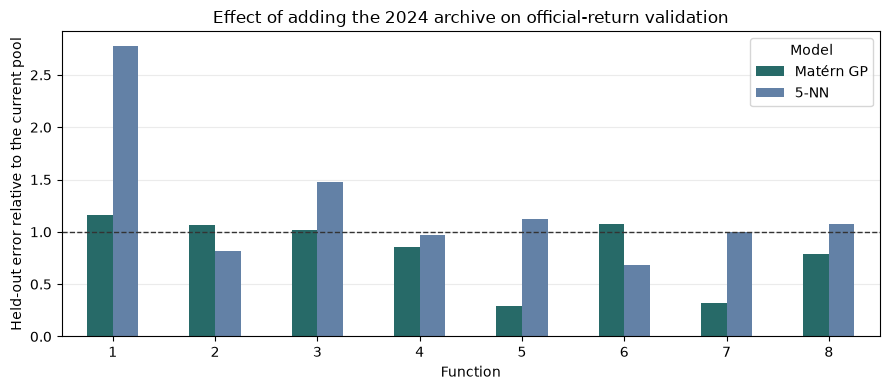

In [4]:
ratios = scores["Relative error"].unstack("Model")
ax = ratios[list(models)].plot.bar(figsize=(9, 4), color=("#276a68", "#6381a6"), rot=0)
ax.axhline(1, color="#333333", linestyle="--", linewidth=1)
ax.set(ylabel="Held-out error relative to the current pool",
       title="Effect of adding the 2024 archive on official-return validation")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.figure.tight_layout()
plt.show()

## Points with strong measured evidence

Repeated measurements matter most when an isolated high score drives a decision. F2's centre was queried repeatedly in 2024. The F6 comparison shows the count and best score within 0.035 Euclidean units of the historical peak. The radius is descriptive and was chosen to inspect evidence in a small neighbourhood. F7 and F8 list the strongest distinct archived coordinates.

In [5]:
for f, point, radius in ((2, [0.5, 0.5], 0.0),
                         (6, [0.424197, 0.368357, 0.648904, 0.762441, 0.113934], 0.035)):
    cols, current, own, archive = datasets[f]
    print(f"Function {f}, distance at most {radius:g} from {point}")
    for scope, frame in (("2024 query returns", archive.loc[archive["position"].gt(0)]),
                         ("Current pool", current)):
        selected = frame.loc[np.linalg.norm(frame[cols].to_numpy() - point, axis=1) <= radius, "y"]
        if len(selected):
            print(f"{scope}: n={len(selected)}, min={selected.min():.9g}, "
                  f"median={selected.median():.9g}, max={selected.max():.9g}")
        else:
            print(f"{scope}: no observations inside this radius")

for f in (7, 8):
    cols, _, _, archive = datasets[f]
    print(f"Function {f} – top five distinct 2024 points")
    distinct = archive.sort_values("y", ascending=False).drop_duplicates(cols).head(5)
    display(distinct[cols + ["y"]].style.format(precision=9))

result = {
    "archive_audit_sha256": sha256((ARCHIVE / "intake-audit.json").read_bytes()).hexdigest(),
    "current_audit_sha256": sha256((CURRENT / "dataset-audit.json").read_bytes()).hexdigest(),
    "counts": counts.reset_index().to_dict(orient="records"),
    "maxima": maxima.reset_index().to_dict(orient="records"),
    "agreement": json.loads(agreement.reset_index().to_json(orient="records", double_precision=15)),
    "validation": scores.reset_index().to_dict(orient="records"),
    "predictions": predictions.to_dict(orient="records"),
}
(ARCHIVE / "analysis-results.json").write_bytes((json.dumps(result, indent=2, allow_nan=False) + "\n").encode())


Function 2, distance at most 0 from [0.5, 0.5]
2024 query returns: n=8, min=0.755709646, median=0.793246773, max=0.919871693
Current pool: no observations inside this radius
Function 6, distance at most 0.035 from [0.424197, 0.368357, 0.648904, 0.762441, 0.113934]
2024 query returns: n=4, min=-0.0648066726, median=-0.0168933396, max=-0.00614358242
Current pool: no observations inside this radius
Function 7 – top five distinct 2024 points


,x1,x2,x3,x4,x5,x6,y
42,0.215055000,0.156395000,0.470335000,0.277514000,0.312339000,0.658909000,3.319276412
93,0.217215000,0.157590000,0.452435000,0.276118000,0.307239000,0.659013000,3.313261090
92,0.215847000,0.159363000,0.447721000,0.276331000,0.307725000,0.662010000,3.310995962
94,0.225971000,0.162570000,0.458913000,0.281655000,0.307708000,0.661830000,3.309523542
82,0.220000000,0.166667000,0.450000000,0.273333000,0.306667000,0.653333000,3.307471944


Function 8 – top five distinct 2024 points


,x1,x2,x3,x4,x5,x6,x7,x8,y
51,0.099319000,0.147425000,0.128446000,0.146356000,0.798274000,0.504534000,0.198957000,0.593679000,9.999943700
52,0.104353000,0.150054000,0.132024000,0.149038000,0.798360000,0.499307000,0.199009000,0.603995000,9.999943499
103,0.098945000,0.148167000,0.132342000,0.144240000,0.800284000,0.499635000,0.198255000,0.580933000,9.999902163
104,0.099802000,0.145820000,0.132512000,0.156556000,0.804737000,0.499757000,0.199474000,0.581027000,9.999872708
102,0.103415000,0.145134000,0.130430000,0.149083000,0.799155000,0.497328000,0.201067000,0.571962000,9.999863215


74579

## Course lifecycle

1. **Define the goal and scope** – compare verified measured scores and quantify what the 2024 cohort contributes for the current eight functions.
2. **Gather the data** – use the pinned public 2024 files and the 25 November current-cohort snapshot.
3. **Explore the data** – compare counts, measured maxima, cross-source agreement and local support.
4. **Clean and preprocess the data** – reconcile cumulative snapshots, retain stable paired records, and quarantine conflicts. Aggregate repeated inputs inside each model training partition.
5. **Select and engineer features** – keep the original numerical coordinates. Use the existing signed-log target for F1.
6. **Define the machine-learning task** – regress the underlying score to assess whether archive training transfers to the current campaign.
7. **Partition the data** – hold out each of the nine official returns per function and withhold all matching coordinates.
8. **Select and train candidate methods** – fit identical fixed Matérn GP and 5-NN methods with and without archive data.
9. **Evaluate and interpret the results** – compare within-function errors and check the measured local evidence.
10. **Deploy and iterate** – deployment is not applicable to this historical study. Retain the measured evidence for the next query decision.